In [13]:
#no2 sửa để giảm overfit ở M2

# **Cell 1: Import thư viện và cấu hình chung**

In [14]:
import os, time, random, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

# Cố định seed để kết quả có thể lặp lại
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Chọn thiết bị: NVIDIA GPU (cuda) -> GPU Apple (mps) -> CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Đang dùng thiết bị:", device)

# Windows chạy notebook hay lỗi khi num_workers > 0, nên đặt 0 cho an toàn
# (Linux/Mac có thể đặt 2 hoặc 4 để nạp dữ liệu nhanh hơn)
NUM_WORKERS = 0

Đang dùng thiết bị: cuda


# **Cell 2: Khai báo đường dẫn dữ liệu**

In [15]:
import os

# Điền thông tin lấy từ file kaggle.json (Kaggle -> Settings -> API -> Create New Token)
os.environ["KAGGLE_USERNAME"] = "Cbac"
os.environ["KAGGLE_KEY"] = "KGAT_39bf36b6e0c21ab2c015416023628e52"

import kagglehub   # phải import SAU khi đã đặt biến môi trường

# Tải dataset về máy (lần sau sẽ dùng lại bản đã tải)
DATA_DIR = kagglehub.dataset_download("msambare/fer2013")
print("Dataset nằm ở:", DATA_DIR)

TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR = os.path.join(DATA_DIR, "test")

print("Các lớp trong train:", sorted(os.listdir(TRAIN_DIR)))
print("Các lớp trong test :", sorted(os.listdir(TEST_DIR)))

Dataset nằm ở: C:\Users\ADMIN\.cache\kagglehub\datasets\msambare\fer2013\versions\1
Các lớp trong train: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Các lớp trong test : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [16]:
#nhập key lúc chạy, không lưu vào code
"""import os
from getpass import getpass

# Hộp nhập sẽ hiện ra khi chạy, giá trị không bị lưu trong file notebook
os.environ["KAGGLE_USERNAME"] = input("Kaggle username: ")
os.environ["KAGGLE_KEY"] = getpass("Kaggle key: ")

import kagglehub
DATA_DIR = kagglehub.dataset_download("msambare/fer2013")"""

'import os\nfrom getpass import getpass\n\n# Hộp nhập sẽ hiện ra khi chạy, giá trị không bị lưu trong file notebook\nos.environ["KAGGLE_USERNAME"] = input("Kaggle username: ")\nos.environ["KAGGLE_KEY"] = getpass("Kaggle key: ")\n\nimport kagglehub\nDATA_DIR = kagglehub.dataset_download("msambare/fer2013")'

# **Cell 3: Thống kê phân bố lớp**

Tên lớp: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
        Lớp  Train  Test
0     angry   3995   958
1   disgust    436   111
2      fear   4097  1024
3     happy   7215  1774
4   neutral   4965  1233
5       sad   4830  1247
6  surprise   3171   831
Tổng train: 28709 | Tổng test: 7178


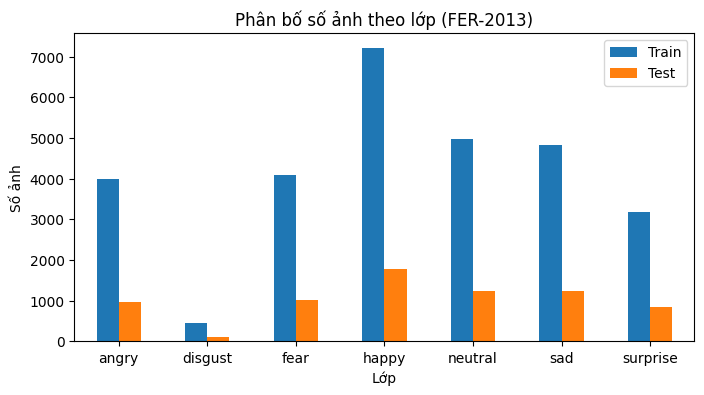

In [17]:
# ImageFolder tự lấy tên lớp từ tên thư mục (sắp xếp theo thứ tự chữ cái)
full_train = datasets.ImageFolder(TRAIN_DIR)
test_raw = datasets.ImageFolder(TEST_DIR)

class_names = full_train.classes
num_classes = len(class_names)
print("Tên lớp:", class_names)

# Đếm số ảnh mỗi lớp
train_counts = np.bincount(full_train.targets, minlength=num_classes)
test_counts = np.bincount(test_raw.targets, minlength=num_classes)

df_count = pd.DataFrame({"Lớp": class_names, "Train": train_counts, "Test": test_counts})
print(df_count)
print("Tổng train:", train_counts.sum(), "| Tổng test:", test_counts.sum())

# Vẽ biểu đồ phân bố
df_count.set_index("Lớp").plot(kind="bar", figsize=(8, 4))
plt.title("Phân bố số ảnh theo lớp (FER-2013)")
plt.ylabel("Số ảnh")
plt.xticks(rotation=0)
plt.show()

# **Cell 4: Xử lý mất cân bằng bằng class weight**

In [18]:
# Lớp ít ảnh (disgust) sẽ có trọng số lớn hơn khi tính loss.
# Công thức: tổng / (số lớp * số ảnh của lớp), rồi lấy căn bậc hai
# để làm mềm, tránh trọng số lớp hiếm quá lớn gây huấn luyện không ổn định.
class_weights = train_counts.sum() / (num_classes * train_counts)
class_weights = np.sqrt(class_weights)
class_weights = torch.tensor(class_weights, dtype=torch.float32)

for name, w in zip(class_names, class_weights):
    print(f"{name:10s} -> trọng số {w:.3f}")

angry      -> trọng số 1.013
disgust    -> trọng số 3.067
fear       -> trọng số 1.001
happy      -> trọng số 0.754
neutral    -> trọng số 0.909
sad        -> trọng số 0.921
surprise   -> trọng số 1.137


# **Cell 5: Hàm tạo DataLoader (có augmentation cho tập train)**

In [19]:
def make_loaders(img_size, channels, mean, std, batch_size=64, strong_aug=False):
    """
    img_size  : kích thước ảnh đầu vào mô hình (vuông)
    channels  : 1 (xám) hoặc 3 (xám lặp lại 3 kênh, dùng cho mô hình pretrained)
    mean, std : danh sách giá trị chuẩn hoá, độ dài = channels
    strong_aug: True -> augmentation mạnh hơn (dùng cho M2 để giảm overfit)
    """
    if strong_aug:
        # Augmentation mạnh hơn: nhưng chỉ tăng "một tí xíu" cho vừa ảnh 48x48
        train_tf = transforms.Compose([
            transforms.Grayscale(num_output_channels=channels),
            # Cắt ngẫu nhiên 80-100% diện tích rồi phóng về img_size
            # (không cắt quá nhỏ vì khuôn mặt FER đã crop sát, cắt nhiều sẽ mất biểu cảm)
            transforms.RandomResizedCrop(img_size, scale=(0.8, 1.0), ratio=(0.9, 1.1)),
            transforms.RandomHorizontalFlip(),
            transforms.RandomRotation(15),                      # xoay tối đa 15 độ (trước là 10)
            transforms.ColorJitter(brightness=0.2, contrast=0.2),  # đổi độ sáng/tương phản nhẹ
            transforms.ToTensor(),
            transforms.Normalize(mean, std),
            # RandomErasing làm việc trên tensor nên phải đặt SAU ToTensor/Normalize
            # p=0.25: chỉ xoá ở 25% ảnh, mỗi lần xoá 2%-10% diện tích
            transforms.RandomErasing(p=0.25, scale=(0.02, 0.10), value=0),
        ])
    else:
        # Augmentation cũ (giữ nguyên cho M1)
        train_tf = transforms.Compose([
            transforms.Grayscale(num_output_channels=channels),
            transforms.Resize((img_size, img_size)),
            transforms.RandomHorizontalFlip(),
            transforms.RandomRotation(10),
            transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
            transforms.ToTensor(),
            transforms.Normalize(mean, std),
        ])

    # Tập val/test: KHÔNG augmentation, chỉ resize + chuẩn hoá
    eval_tf = transforms.Compose([
        transforms.Grayscale(num_output_channels=channels),
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])

    # Hai bản dataset trên cùng thư mục train, chỉ khác transform
    train_ds = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
    val_ds = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)
    test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)

    # Tách 10% tập train làm validation, giữ nguyên tỉ lệ lớp (stratify)
    idx_train, idx_val = train_test_split(
        np.arange(len(train_ds)), test_size=0.1,
        stratify=train_ds.targets, random_state=SEED)

    train_loader = DataLoader(Subset(train_ds, idx_train), batch_size=batch_size,
                              shuffle=True, num_workers=NUM_WORKERS)
    val_loader = DataLoader(Subset(val_ds, idx_val), batch_size=batch_size,
                            shuffle=False, num_workers=NUM_WORKERS)
    test_loader = DataLoader(test_ds, batch_size=batch_size,
                             shuffle=False, num_workers=NUM_WORKERS)

    print(f"Train: {len(idx_train)} | Val: {len(idx_val)} | Test: {len(test_ds)}")
    return train_loader, val_loader, test_loader, test_ds

# **Cell 6: Định nghĩa mô hình M1 (CNN tự thiết kế) và M2 (ResNet18)**

In [20]:
# ---------- M1: CNN tự thiết kế ----------
class EmotionCNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()

        # Một khối gồm: Conv-BN-ReLU (x2) -> Pooling -> Dropout
        def block(c_in, c_out, drop):
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
                nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
                nn.MaxPool2d(2),
                nn.Dropout(drop),
            )

        # Ảnh 1x48x48 -> sau 4 lần pooling còn 256x3x3
        self.features = nn.Sequential(
            block(1, 32, 0.2),
            block(32, 64, 0.25),
            block(64, 128, 0.3),
            block(128, 256, 0.3),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 3 * 3, 256), nn.BatchNorm1d(256), nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


# ---------- M2: Transfer learning với ResNet18 ----------
def build_resnet18(num_classes=7, dropout=0.3, freeze_early=False):
    # Tải trọng số pretrained trên ImageNet (cần bật Internet)
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

    # Đóng băng các lớp đầu (đặc trưng cạnh/góc rất chung, không cần học lại)
    # -> ít tham số cần học hơn -> bớt overfit
    if freeze_early:
        for module in [model.conv1, model.bn1, model.layer1]:
            for p in module.parameters():
                p.requires_grad = False

    # Thay lớp cuối để phân loại 7 cảm xúc
    model.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(model.fc.in_features, num_classes))
    return model

def count_params(model):
    return sum(p.numel() for p in model.parameters())

print("Số tham số M1:", count_params(EmotionCNN()))
print("Số tham số M2:", count_params(build_resnet18()))

Số tham số M1: 1765991
Số tham số M2: 11180103


# **Cell 7: Hàm huấn luyện và đánh giá**

In [21]:
def run_epoch(model, loader, criterion, optimizer=None):
    """Chạy 1 epoch. Có optimizer -> huấn luyện, không có -> chỉ đánh giá."""
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(is_train):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += images.size(0)

    return total_loss / total, correct / total


def train_model(model, train_loader, val_loader, epochs, lr, weight_decay=1e-4, label_smoothing=0.0):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device),label_smoothing=label_smoothing)
        # Chỉ đưa vào optimizer những tham số không bị đóng băng
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(params, lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_acc, best_state = 0.0, None

    for epoch in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        scheduler.step()

        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(va_acc)

        # Lưu lại trọng số tốt nhất theo val accuracy
        if va_acc > best_acc:
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())

        print(f"Epoch {epoch+1:2d}/{epochs} | "
              f"train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
              f"val loss {va_loss:.3f} acc {va_acc:.3f} | {time.time()-t0:.0f}s")

    model.load_state_dict(best_state)  # nạp lại bản tốt nhất
    print("Val accuracy tốt nhất:", round(best_acc, 4))
    return model, history


@torch.no_grad()
def predict_all(model, loader):
    """Dự đoán toàn bộ tập, trả về nhãn thật và nhãn dự đoán."""
    model.eval()
    y_true, y_pred = [], []
    for images, labels in loader:
        outputs = model(images.to(device))
        y_pred.extend(outputs.argmax(1).cpu().numpy())
        y_true.extend(labels.numpy())
    return np.array(y_true), np.array(y_pred)

# **Cell 8: Huấn luyện M1 (CNN tự thiết kế)**

In [22]:

# Ảnh xám 1 kênh, 48x48, chuẩn hoá về khoảng [-1, 1]
train_loader1, val_loader1, test_loader1, test_ds1 = make_loaders(
    img_size=48, channels=1, mean=[0.5], std=[0.5])

model1 = EmotionCNN(num_classes)
model1, hist1 = train_model(model1, train_loader1, val_loader1, epochs=40, lr=1e-3)


Train: 25838 | Val: 2871 | Test: 7178
Epoch  1/40 | train loss 1.821 acc 0.287 | val loss 1.586 acc 0.415 | 51s
Epoch  2/40 | train loss 1.521 acc 0.439 | val loss 1.414 acc 0.494 | 57s
Epoch  3/40 | train loss 1.407 acc 0.482 | val loss 1.291 acc 0.517 | 49s
Epoch  4/40 | train loss 1.341 acc 0.505 | val loss 1.265 acc 0.539 | 49s
Epoch  5/40 | train loss 1.294 acc 0.527 | val loss 1.216 acc 0.570 | 41s
Epoch  6/40 | train loss 1.269 acc 0.531 | val loss 1.192 acc 0.570 | 52s
Epoch  7/40 | train loss 1.235 acc 0.544 | val loss 1.204 acc 0.557 | 52s
Epoch  8/40 | train loss 1.214 acc 0.555 | val loss 1.129 acc 0.592 | 48s
Epoch  9/40 | train loss 1.183 acc 0.564 | val loss 1.108 acc 0.593 | 40s
Epoch 10/40 | train loss 1.172 acc 0.570 | val loss 1.135 acc 0.590 | 39s
Epoch 11/40 | train loss 1.153 acc 0.577 | val loss 1.162 acc 0.586 | 39s
Epoch 12/40 | train loss 1.139 acc 0.582 | val loss 1.083 acc 0.612 | 39s
Epoch 13/40 | train loss 1.119 acc 0.590 | val loss 1.076 acc 0.619 | 38s


# **Cell 9: Huấn luyện M2 (ResNet18 transfer learning)**

In [23]:
# ResNet18 cần ảnh 3 kênh: ảnh xám được lặp lại 3 kênh,
# chuẩn hoá theo mean/std của ImageNet, phóng to lên 96x96 cho hợp với mô hình
IMNET_MEAN = [0.485, 0.456, 0.406]
IMNET_STD = [0.229, 0.224, 0.225]

# strong_aug=True: bật augmentation mạnh hơn cho M2
train_loader2, val_loader2, test_loader2, test_ds2 = make_loaders(
    img_size=96, channels=3, mean=IMNET_MEAN, std=IMNET_STD, strong_aug=True)

model2 = build_resnet18(num_classes, dropout=0.5, freeze_early=True)
# weight_decay=0.05: mức hợp lý cho AdamW (1e-2 quá nhỏ vì còn bị nhân với lr)
model2, hist2 = train_model(model2, train_loader2, val_loader2,
                            epochs=12, lr=3e-4,
                            weight_decay=0.05, label_smoothing=0.1)

Train: 25838 | Val: 2871 | Test: 7178
Epoch  1/12 | train loss 1.721 acc 0.452 | val loss 1.456 acc 0.571 | 87s
Epoch  2/12 | train loss 1.469 acc 0.566 | val loss 1.397 acc 0.600 | 86s
Epoch  3/12 | train loss 1.396 acc 0.600 | val loss 1.337 acc 0.629 | 83s
Epoch  4/12 | train loss 1.341 acc 0.629 | val loss 1.333 acc 0.637 | 87s
Epoch  5/12 | train loss 1.304 acc 0.644 | val loss 1.303 acc 0.653 | 86s
Epoch  6/12 | train loss 1.257 acc 0.670 | val loss 1.299 acc 0.651 | 85s
Epoch  7/12 | train loss 1.214 acc 0.690 | val loss 1.299 acc 0.667 | 86s
Epoch  8/12 | train loss 1.165 acc 0.714 | val loss 1.277 acc 0.670 | 85s
Epoch  9/12 | train loss 1.121 acc 0.732 | val loss 1.270 acc 0.677 | 86s
Epoch 10/12 | train loss 1.076 acc 0.757 | val loss 1.265 acc 0.674 | 85s
Epoch 11/12 | train loss 1.042 acc 0.773 | val loss 1.274 acc 0.674 | 86s
Epoch 12/12 | train loss 1.017 acc 0.785 | val loss 1.276 acc 0.677 | 86s
Val accuracy tốt nhất: 0.6771


# **Cell 10: Đồ thị huấn luyện (M5)**

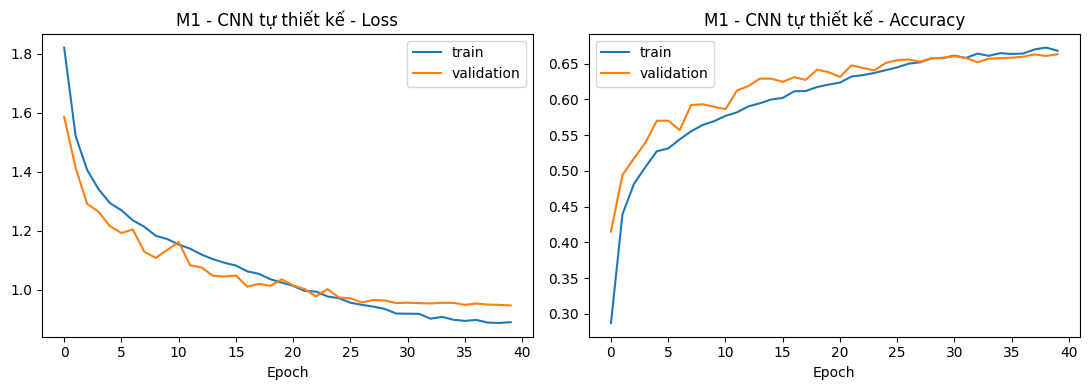

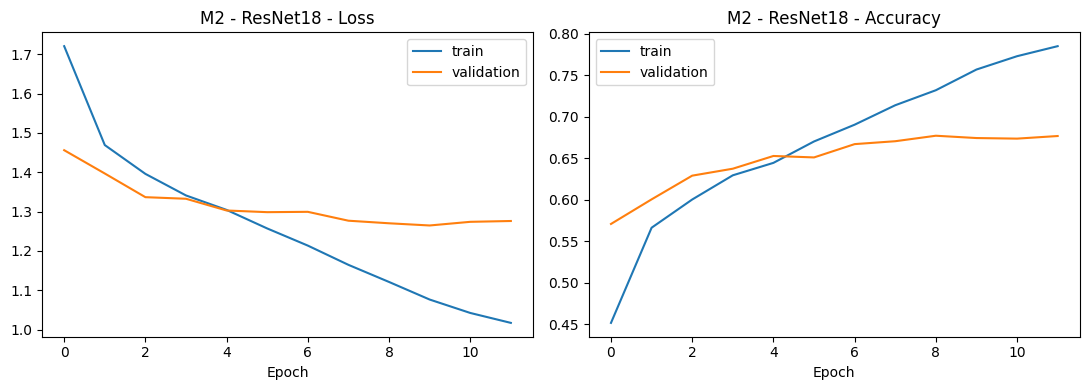

In [24]:
def plot_history(hist, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].plot(hist["train_loss"], label="train")
    axes[0].plot(hist["val_loss"], label="validation")
    axes[0].set_title(f"{title} - Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(hist["train_acc"], label="train")
    axes[1].plot(hist["val_acc"], label="validation")
    axes[1].set_title(f"{title} - Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

plot_history(hist1, "M1 - CNN tự thiết kế")
plot_history(hist2, "M2 - ResNet18")

# **Cell 11: Đánh giá trên tập test và confusion matrix (M1, M2, M4)**

===== M1 - CNN =====
Accuracy : 0.6647
Macro F1 : 0.6337
              precision    recall  f1-score   support

       angry      0.605     0.554     0.578       958
     disgust      0.510     0.667     0.578       111
        fear      0.534     0.396     0.455      1024
       happy      0.870     0.876     0.873      1774
     neutral      0.575     0.697     0.630      1233
         sad      0.560     0.532     0.546      1247
    surprise      0.734     0.824     0.777       831

    accuracy                          0.665      7178
   macro avg      0.627     0.649     0.634      7178
weighted avg      0.661     0.665     0.660      7178



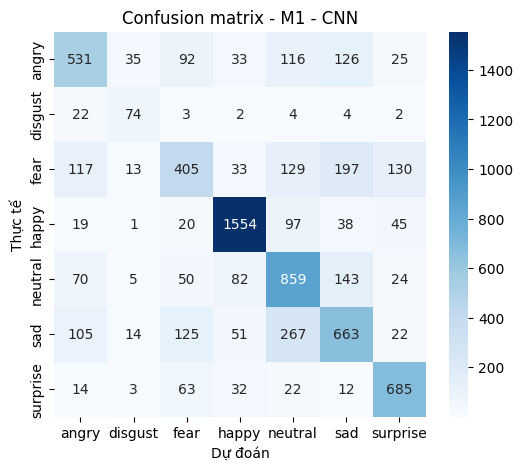

===== M2 - ResNet18 =====
Accuracy : 0.6757
Macro F1 : 0.6586
              precision    recall  f1-score   support

       angry      0.575     0.598     0.586       958
     disgust      0.697     0.622     0.657       111
        fear      0.570     0.456     0.507      1024
       happy      0.889     0.857     0.873      1774
     neutral      0.612     0.656     0.633      1233
         sad      0.548     0.588     0.567      1247
    surprise      0.759     0.817     0.787       831

    accuracy                          0.676      7178
   macro avg      0.664     0.656     0.659      7178
weighted avg      0.677     0.676     0.675      7178



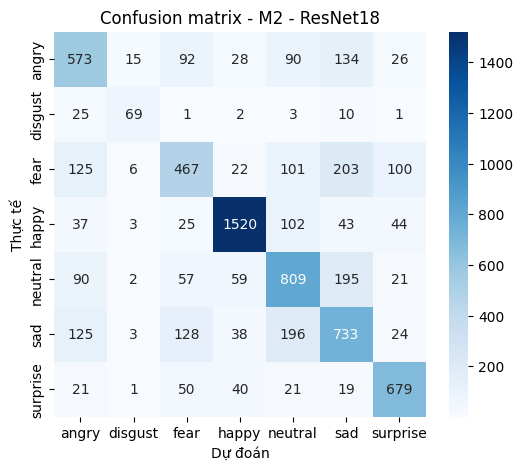

In [25]:
def evaluate(model, test_loader, title):
    y_true, y_pred = predict_all(model, test_loader)

    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average="macro")
    print(f"===== {title} =====")
    print(f"Accuracy : {acc:.4f}")
    print(f"Macro F1 : {f1:.4f}")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f"Confusion matrix - {title}")
    plt.xlabel("Dự đoán")
    plt.ylabel("Thực tế")
    plt.show()

    return acc, f1, y_true, y_pred

acc1, f1_1, y_true1, y_pred1 = evaluate(model1, test_loader1, "M1 - CNN")
acc2, f1_2, y_true2, y_pred2 = evaluate(model2, test_loader2, "M2 - ResNet18")

# **Cell 12: Xem các ảnh dự đoán sai (M4: ít nhất 10 ảnh)**

M1 - CNN: sai 2407/7178 ảnh


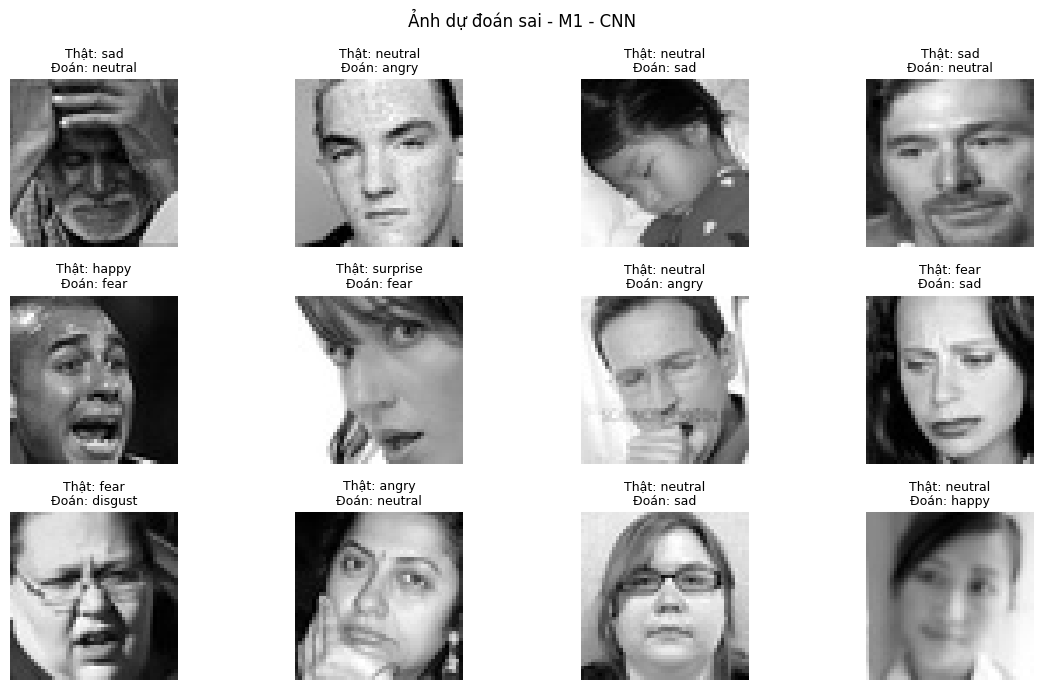

M2 - ResNet18: sai 2328/7178 ảnh


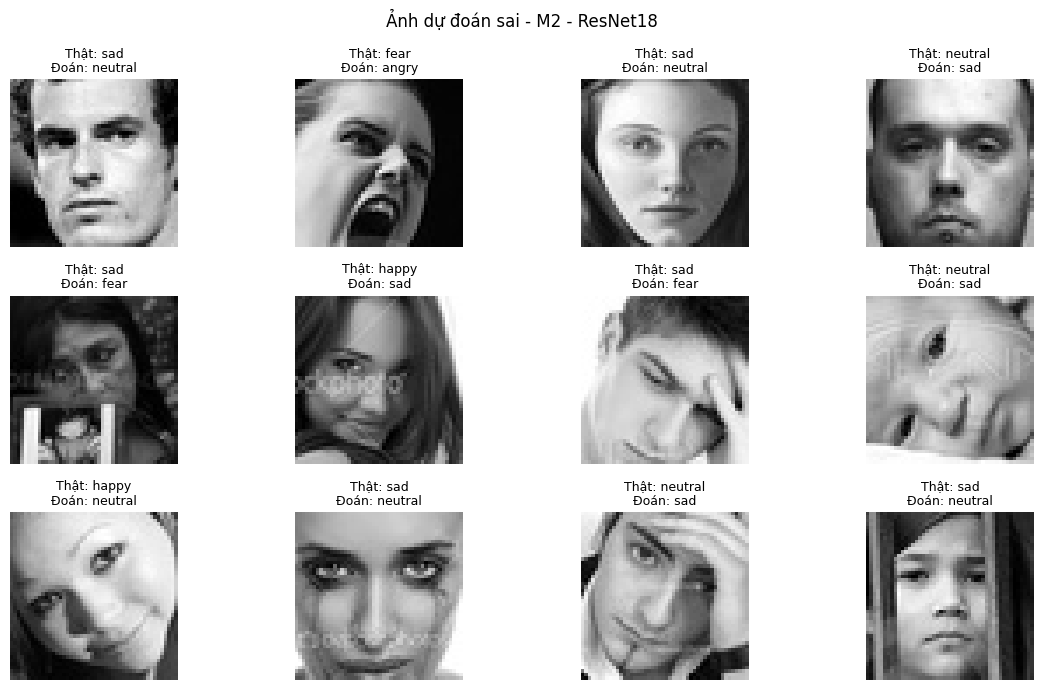

In [26]:
def show_wrong(test_ds, y_true, y_pred, title, n=12):
    # Lấy vị trí các ảnh bị dự đoán sai
    wrong_idx = np.where(y_true != y_pred)[0]
    print(f"{title}: sai {len(wrong_idx)}/{len(y_true)} ảnh")

    # Chọn ngẫu nhiên n ảnh sai để xem
    rng = np.random.RandomState(SEED)
    chosen = rng.choice(wrong_idx, size=n, replace=False)

    plt.figure(figsize=(12, 7))
    for i, idx in enumerate(chosen):
        path = test_ds.samples[idx][0]          # đường dẫn ảnh gốc
        img = Image.open(path)
        plt.subplot(3, 4, i + 1)
        plt.imshow(img, cmap="gray")
        plt.title(f"Thật: {class_names[y_true[idx]]}\nĐoán: {class_names[y_pred[idx]]}", fontsize=9)
        plt.axis("off")
    plt.suptitle(f"Ảnh dự đoán sai - {title}")
    plt.tight_layout()
    plt.show()

show_wrong(test_ds1, y_true1, y_pred1, "M1 - CNN")
show_wrong(test_ds2, y_true2, y_pred2, "M2 - ResNet18")

# **Cell 13: Bảng so sánh M1 và M2 (M3: accuracy, macro F1, số tham số, FPS)**

In [27]:
def measure_fps(model, input_shape, n=100):
    """Đo FPS trên CPU với 1 ảnh/lần (giống lúc chạy realtime)."""
    m = copy.deepcopy(model).cpu().eval()
    x = torch.randn(1, *input_shape)
    with torch.no_grad():
        for _ in range(10):      # chạy khởi động
            m(x)
        t0 = time.time()
        for _ in range(n):
            m(x)
    return n / (time.time() - t0)

fps1 = measure_fps(model1, (1, 48, 48))
fps2 = measure_fps(model2, (3, 96, 96))

df_compare = pd.DataFrame({
    "Mô hình": ["M1 - CNN tự thiết kế", "M2 - ResNet18 (transfer)"],
    "Accuracy": [round(acc1, 4), round(acc2, 4)],
    "Macro F1": [round(f1_1, 4), round(f1_2, 4)],
    "Số tham số": [count_params(model1), count_params(model2)],
    "FPS (CPU)": [round(fps1, 1), round(fps2, 1)],
})
df_compare
# Cần đo lại trên labtop

,Mô hình,Accuracy,Macro F1,Số tham số,FPS (CPU)
0,M1 - CNN tự thiết kế,0.6647,0.6337,1765991,220.2
1,M2 - ResNet18 (transfer),0.6757,0.6586,11180103,39.0


# **Cell 14: Lưu trọng số mô hình**

In [28]:
# Lưu vào thư mục weights/ cạnh file notebook (đúng cấu trúc nộp bài)
os.makedirs("../weights", exist_ok=True)   # notebook nằm trong notebooks/ nên lùi 1 cấp

torch.save({"state_dict": model1.state_dict(), "class_names": class_names},
           "../weights/m1_cnn.pth")
torch.save({"state_dict": model2.state_dict(), "class_names": class_names},
           "../weights/m2_resnet18.pth")

print("Đã lưu:", os.listdir("../weights"))
print("Thứ tự lớp:", class_names)

Đã lưu: ['m1_cnn.pth', 'm2_resnet18.pth']
Thứ tự lớp: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
